# Predicting Vehicle Prices Using Regression Models

## **Objectives**  
The primary goal of this project is to develop a robust regression model to predict used car prices for a reseller based on various listed features and specifications. In addition to predicting prices, the project focuses on identifying feature importance and mitigating overfitting through the application of regularisation techniques.

There can be several business objectives for this, such as:

* **Price Prediction**: Model car prices based on features like mileage, fuel type, and performance.
* **Market Analysis**: Explore trends and preferences in the used car market, by type, region, or other metrics.
* **Feature Importance**: Identify the most important factors influencing car prices (e.g., fuel type, mileage, age).

### **Tasks Overview**
The data pipeline for this task involves the following steps:  
1. **Dataset Overview**   
2. **Data Preprocessing**
3. **Data Visualisation & Exploration**
4. **Model Building**
3. **Regularisation**

## **1 Data Understanding**

| **Variable** | **Description** |
--------|--------------|
| `make_model` | The brand and model of the vehicle (e.g., 'Audi A1'). |
| `body_type` | The body style of the vehicle, such as Sedan, Compact, or Station Wagon. |
| `price`  | The listed price of the car in currency. |
| `vat`  | Indicates the VAT status for the vehicle's price (e.g., VAT deductible, Price negotiable). |
| `km` | The total mileage (in kilometers) of the vehicle, indicating its usage. |
| `Type` | Condition of the vehicle, whether it's 'Used' or 'New'.|
| `Fuel` | Type of fuel the vehicle uses, such as 'Diesel', 'Benzine', etc. |
| `Gears` | The number of gears in the vehicle's transmission. |
| `Comfort_Convenience` | Comfort and convenience features, such as 'Air conditioning', 'Leather steering wheel', 'Cruise control', and more. |
| `Entertainment_Media` | Media features available in the vehicle, including 'Bluetooth', 'MP3', 'Radio', etc. |
| `Extras` | Additional features like 'Alloy wheels', 'Sport suspension', etc.|
| `Safety_Security` | Safety features like 'ABS', 'Airbags', 'Electronic stability control', 'Isofix', etc.  |
| `age` | Age of the car (calculated based on the model year). |
| `Previous_Owners`| The number of previous owners the car has had. |
| `hp_kW` | Engine power in kilowatts (kW), indicating the performance capacity of the engine.|
| `Inspection_new` | Indicates whether the car has recently undergone an inspection (1 for yes, 0 for no). |
| `Paint_Type`| The type of paint on the car, such as 'Metallic', 'Matte', etc. |
| `Upholstery_type` | The material used for the interior upholstery, such as 'Cloth', 'Leather', etc.|
| `Gearing_Type` | The type of transmission the car uses, either 'Automatic' or 'Manual'. |
| `Displacement_cc` | The engine displacement in cubic centimeters (cc), indicating the size of the engine.|
| `Weight_kg` | The total weight of the vehicle in kilograms.|
| `Drive_chain` | The type of drivetrain, indicating whether it's 'Front' or 'Rear' wheel drive. |
| `cons_comb`  | The combined fuel consumption in liters per 100 kilometers.|

### **1.1 Data Loading**

**Importing Necessary Libraries**

In [1]:
# Importing necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.model_selection import GridSearchCV
import warnings
warnings.filterwarnings("ignore")



#### **1.1.1**
Load the dataset

In [2]:
# Load the data
from google.colab import drive
drive.mount('/content/drive')
df=pd.read_csv('/content/drive/MyDrive/Regression_Project/Car_Price_data.csv')



Mounted at /content/drive


In [3]:
df.head(3)

,make_model,body_type,price,vat,km,Type,Fuel,Gears,Comfort_Convenience,Entertainment_Media,...,Previous_Owners,hp_kW,Inspection_new,Paint_Type,Upholstery_type,Gearing_Type,Displacement_cc,Weight_kg,Drive_chain,cons_comb
0,Audi A1,Sedans,15770,VAT deductible,56013.0,Used,Diesel,7.0,"Air conditioning,Armrest,Automatic climate con...","Bluetooth,Hands-free equipment,On-board comput...",...,2.0,66.0,1,Metallic,Cloth,Automatic,1422.0,1220.0,front,3.8
1,Audi A1,Sedans,14500,Price negotiable,80000.0,Used,Benzine,7.0,"Air conditioning,Automatic climate control,Hil...","Bluetooth,Hands-free equipment,On-board comput...",...,1.0,141.0,0,Metallic,Cloth,Automatic,1798.0,1255.0,front,5.6
2,Audi A1,Sedans,14640,VAT deductible,83450.0,Used,Diesel,7.0,"Air conditioning,Cruise control,Electrical sid...","MP3,On-board computer",...,1.0,85.0,0,Metallic,Cloth,Automatic,1598.0,1135.0,front,3.8


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15915 entries, 0 to 15914
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   make_model           15915 non-null  object 
 1   body_type            15915 non-null  object 
 2   price                15915 non-null  int64  
 3   vat                  15915 non-null  object 
 4   km                   15915 non-null  float64
 5   Type                 15915 non-null  object 
 6   Fuel                 15915 non-null  object 
 7   Gears                15915 non-null  float64
 8   Comfort_Convenience  15915 non-null  object 
 9   Entertainment_Media  15915 non-null  object 
 10  Extras               15915 non-null  object 
 11  Safety_Security      15915 non-null  object 
 12  age                  15915 non-null  float64
 13  Previous_Owners      15915 non-null  float64
 14  hp_kW                15915 non-null  float64
 15  Inspection_new       15915 non-null 

In [5]:
df.columns

Index(['make_model', 'body_type', 'price', 'vat', 'km', 'Type', 'Fuel',
       'Gears', 'Comfort_Convenience', 'Entertainment_Media', 'Extras',
       'Safety_Security', 'age', 'Previous_Owners', 'hp_kW', 'Inspection_new',
       'Paint_Type', 'Upholstery_type', 'Gearing_Type', 'Displacement_cc',
       'Weight_kg', 'Drive_chain', 'cons_comb'],
      dtype='object')

In [6]:
df.describe()

,price,km,Gears,age,Previous_Owners,hp_kW,Inspection_new,Displacement_cc,Weight_kg,cons_comb
count,15915.000000,15915.000000,15915.000000,15915.000000,15915.000000,15915.000000,15915.000000,15915.000000,15915.000000,15915.000000
mean,18024.380584,32089.995708,5.937355,1.389695,1.042853,88.499340,0.247063,1428.661891,1337.700534,4.832124
std,7381.679318,36977.214964,0.704772,1.121306,0.339178,26.674341,0.431317,275.804272,199.682385,0.867530
min,4950.000000,0.000000,5.000000,0.000000,0.000000,40.000000,0.000000,890.000000,840.000000,3.000000
25%,12850.000000,1920.500000,5.000000,0.000000,1.000000,66.000000,0.000000,1229.000000,1165.000000,4.100000
50%,16900.000000,20413.000000,6.000000,1.000000,1.000000,85.000000,0.000000,1461.000000,1295.000000,4.800000
75%,21900.000000,46900.000000,6.000000,2.000000,1.000000,103.000000,0.000000,1598.000000,1472.000000,5.400000
max,74600.000000,317000.000000,8.000000,3.000000,4.000000,294.000000,1.000000,2967.000000,2471.000000,9.100000


In [7]:
df.shape

(15915, 23)

## **2 Analysis and Feature Engineering** <font color =red> [35 marks] </font>



### **2.1 Preliminary Analysis and Frequency Distributions** <font color = red> [13 marks] </font>

#### **2.1.1** <font color =red> [1 marks] </font>
Check and fix missing values.

In [8]:
# Find the proportion of missing values in each column and handle if found
df.isnull().sum()/len(df)


,0
make_model,0.0
body_type,0.0
price,0.0
vat,0.0
km,0.0
Type,0.0
Fuel,0.0
Gears,0.0
Comfort_Convenience,0.0
Entertainment_Media,0.0


**From the features, identify the target feature and numerical and categorical predictors. Select the numerical and categorical features carefully as they will be used in analysis.**

#### **2.1.2** <font color =red> [3 marks] </font>
Identify numerical predictors and plot their frequency distributions.

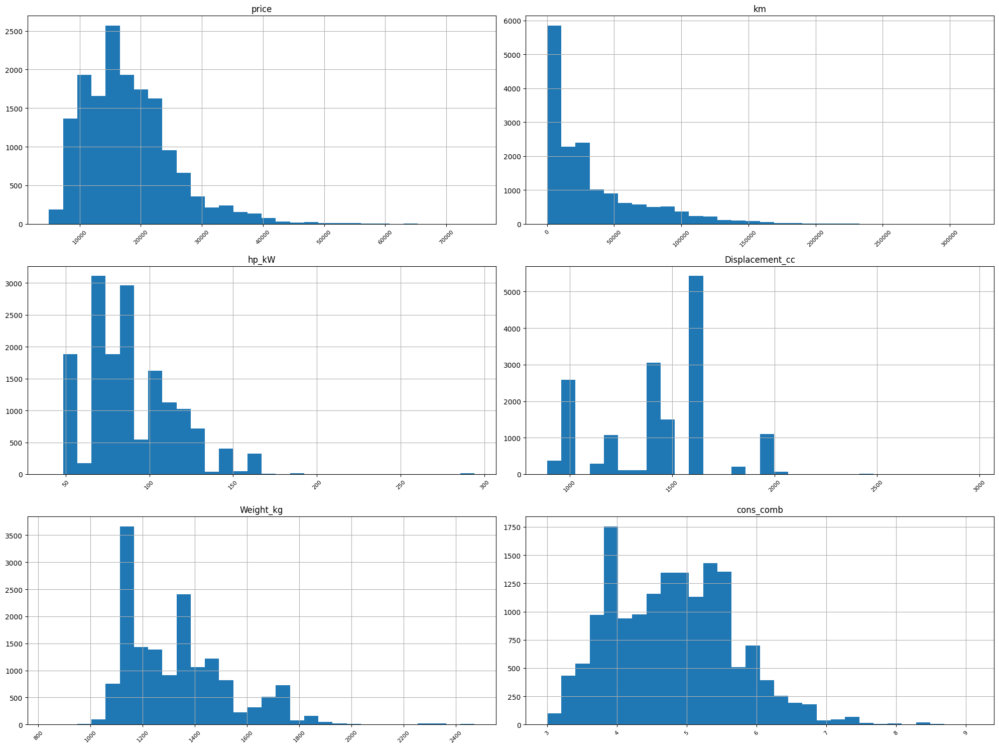

In [9]:
# Identify numerical features and plot histograms
df_num=df[['price','km','hp_kW','Displacement_cc','Weight_kg','cons_comb']]

df_num.hist(figsize=(20, 15), bins=30)

# Fix overlapping x-axis labels for all subplots
for ax in plt.gcf().get_axes():
    ax.tick_params(axis='x', rotation=45, labelsize=8)

plt.tight_layout()
plt.show()

#Gears,age,Previous_Owners,Inpensception_new

#### **2.1.3** <font color =red> [3 marks] </font>
Identify categorical predictors and plot their frequency distributions.

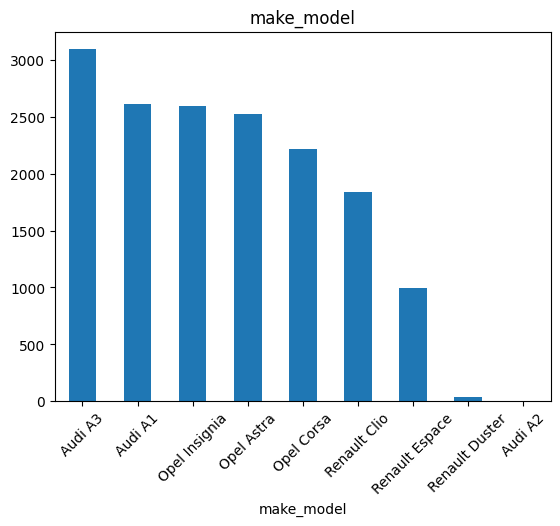

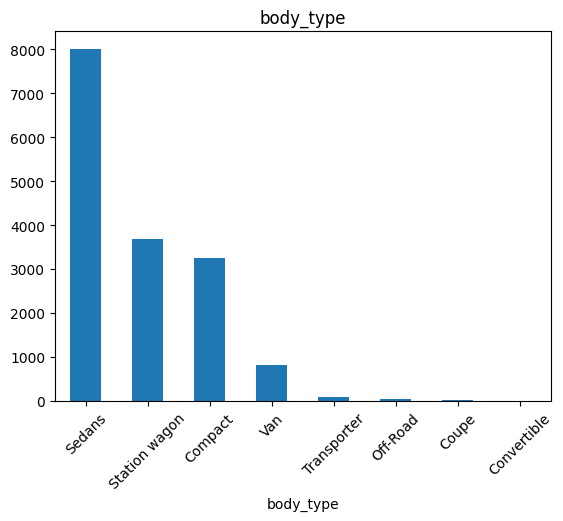

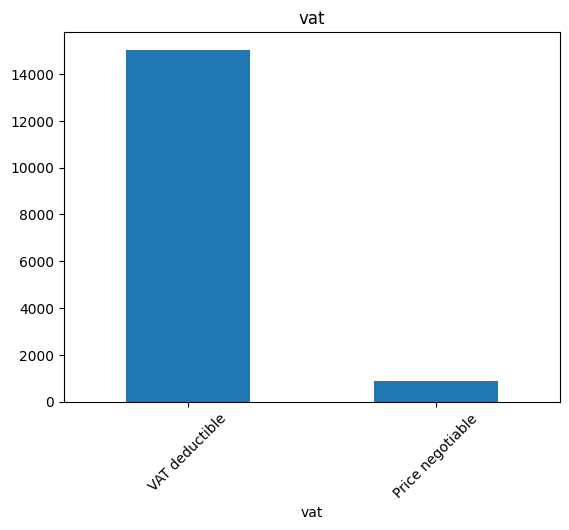

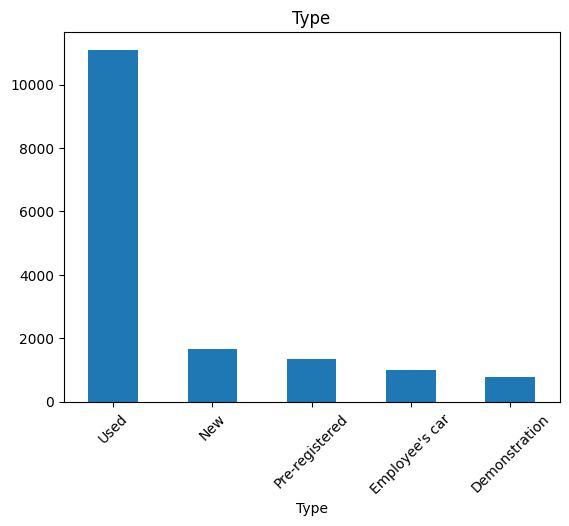

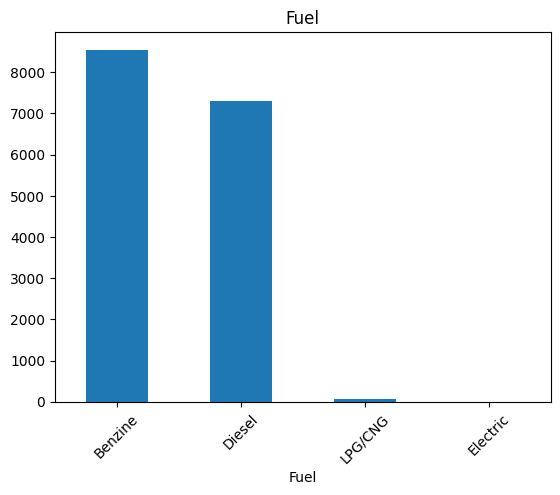

...

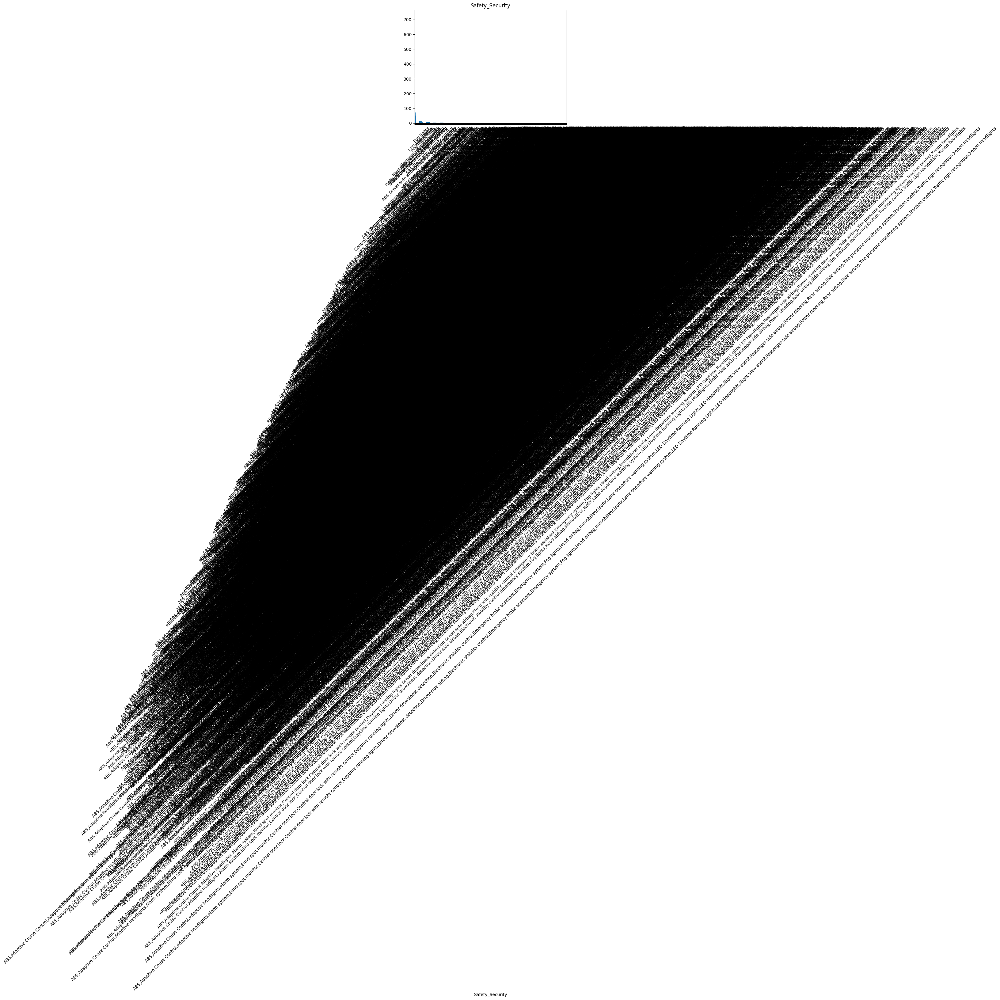

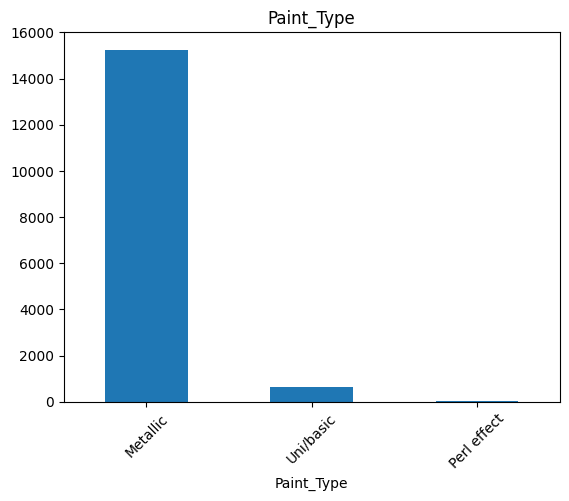

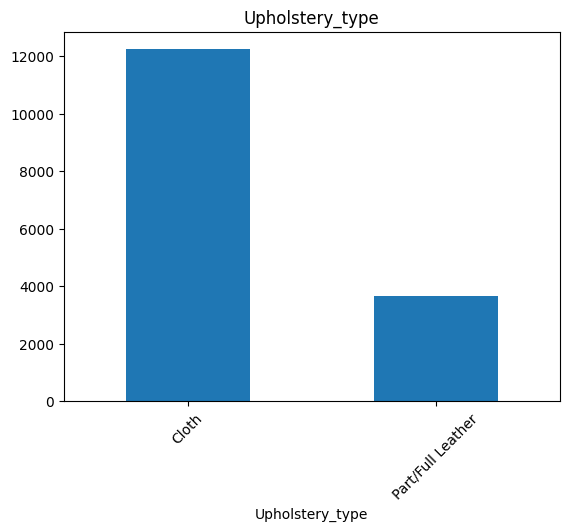

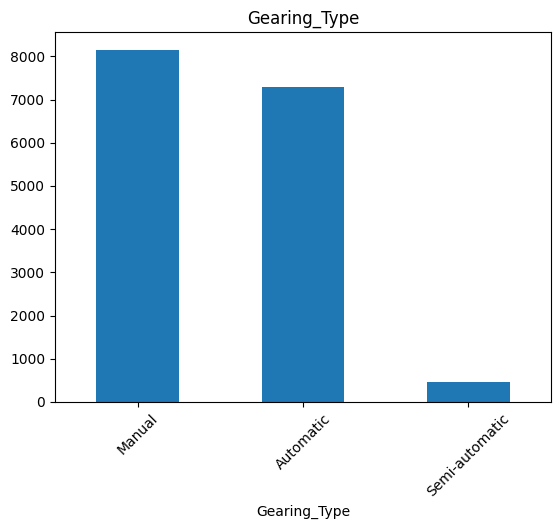

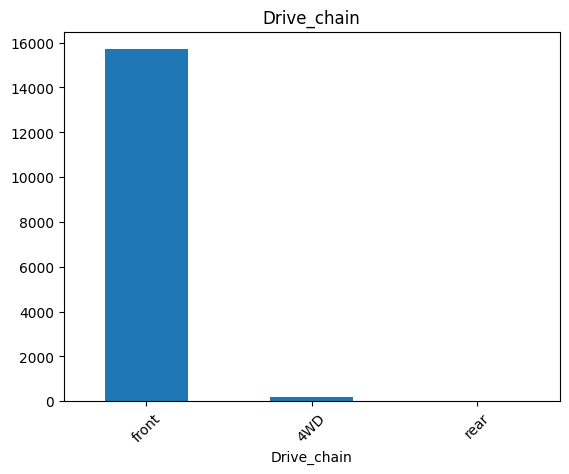

In [10]:
# Identify categorical columns and check their frequency distributions
category=['Gears','age','Previous_Owners','Inspection_new']
df_cat = df.select_dtypes(include=['object','category'])

for col in df_cat.columns:
    df_cat[col].value_counts().plot(kind='bar', title=col)
    plt.xticks(rotation=45)
    plt.show()




**Note**: Look carefully at the values stored in columns `["Comfort_Convenience", "Entertainment_Media", "Extras", "Safety_Security"]`.

Should they be considered categorical? Should they be dropped or handled any other way?

In [11]:
#categorical columns  ["Comfort_Convenience", "Entertainment_Media", "Extras", "Safety_Security"]. should  not be considered as categorical because
#of too many  unique features so we can extract features count as this is regression modeldf['num_extras'] = df['Extras'].apply(lambda x: len(str(x).split(',')))
df['num_safety'] = df['Safety_Security'].apply(lambda x: len(str(x).split(',')))
df['num_comfort'] = df['Comfort_Convenience'].apply(lambda x: len(str(x).split(',')))
df['num_media'] = df['Entertainment_Media'].apply(lambda x: len(str(x).split(',')))

In [12]:
df.head(5)

,make_model,body_type,price,vat,km,Type,Fuel,Gears,Comfort_Convenience,Entertainment_Media,...,Paint_Type,Upholstery_type,Gearing_Type,Displacement_cc,Weight_kg,Drive_chain,cons_comb,num_safety,num_comfort,num_media
0,Audi A1,Sedans,15770,VAT deductible,56013.0,Used,Diesel,7.0,"Air conditioning,Armrest,Automatic climate con...","Bluetooth,Hands-free equipment,On-board comput...",...,Metallic,Cloth,Automatic,1422.0,1220.0,front,3.8,14,16,4
1,Audi A1,Sedans,14500,Price negotiable,80000.0,Used,Benzine,7.0,"Air conditioning,Automatic climate control,Hil...","Bluetooth,Hands-free equipment,On-board comput...",...,Metallic,Cloth,Automatic,1798.0,1255.0,front,5.6,15,9,5
2,Audi A1,Sedans,14640,VAT deductible,83450.0,Used,Diesel,7.0,"Air conditioning,Cruise control,Electrical sid...","MP3,On-board computer",...,Metallic,Cloth,Automatic,1598.0,1135.0,front,3.8,12,13,2
3,Audi A1,Sedans,14500,VAT deductible,73000.0,Used,Diesel,6.0,"Air suspension,Armrest,Auxiliary heating,Elect...","Bluetooth,CD player,Hands-free equipment,MP3,O...",...,Metallic,Cloth,Automatic,1422.0,1195.0,front,3.8,14,16,8
4,Audi A1,Sedans,16790,VAT deductible,16200.0,Used,Diesel,7.0,"Air conditioning,Armrest,Automatic climate con...","Bluetooth,CD player,Hands-free equipment,MP3,O...",...,Metallic,Cloth,Automatic,1422.0,1135.0,front,4.1,13,13,7


#### **2.1.4** <font color =red> [3 marks] </font>
Fix columns with low frequency values and class imbalances.

In [13]:
df = df.drop([
    'Comfort_Convenience',
    'Entertainment_Media',
    'Extras',
    'Safety_Security'
], axis=1)

In [14]:
df.head(5)

,make_model,body_type,price,vat,km,Type,Fuel,Gears,age,Previous_Owners,...,Paint_Type,Upholstery_type,Gearing_Type,Displacement_cc,Weight_kg,Drive_chain,cons_comb,num_safety,num_comfort,num_media
0,Audi A1,Sedans,15770,VAT deductible,56013.0,Used,Diesel,7.0,3.0,2.0,...,Metallic,Cloth,Automatic,1422.0,1220.0,front,3.8,14,16,4
1,Audi A1,Sedans,14500,Price negotiable,80000.0,Used,Benzine,7.0,2.0,1.0,...,Metallic,Cloth,Automatic,1798.0,1255.0,front,5.6,15,9,5
2,Audi A1,Sedans,14640,VAT deductible,83450.0,Used,Diesel,7.0,3.0,1.0,...,Metallic,Cloth,Automatic,1598.0,1135.0,front,3.8,12,13,2
3,Audi A1,Sedans,14500,VAT deductible,73000.0,Used,Diesel,6.0,3.0,1.0,...,Metallic,Cloth,Automatic,1422.0,1195.0,front,3.8,14,16,8
4,Audi A1,Sedans,16790,VAT deductible,16200.0,Used,Diesel,7.0,3.0,1.0,...,Metallic,Cloth,Automatic,1422.0,1135.0,front,4.1,13,13,7


In [15]:
df.shape

(15915, 22)

Some information regarding values in the `Type` column that may help:
- *'Pre-registered'* cars are ones which have already been registered previously by the seller.
- *'New'* cars are not necessarily new cars, but new-like cars. These might also have multiple owners due to multiple pre-registrations as well.
- *'Employee's car'* are cars used by employees over a short period of time and small distance.
- *'Demonstration'* cars are used for trial purposes and also driven for a short time and distance.

Based on these, you can handle this particular column. For other columns, decide a strategy on your own.

In [16]:
df["Type"].unique()

array(['Used', "Employee's car", 'New', 'Demonstration', 'Pre-registered'],
      dtype=object)

In [17]:
df['Type'] = df['Type'].replace({
    'Pre-registered': 'Almost New',
    'New': 'Almost New',
    "Employee's car": 'Almost New',
    'Demonstration': 'Almost New'
})

In [18]:
df['Type']

,Type
0,Used
1,Used
2,Used
3,Used
4,Used
...,...
15910,Almost New
15911,Used
15912,Almost New
15913,Almost New


In [19]:
#fuel column major are dieseland benzene

df['Fuel'] = df['Fuel'].replace({
    'LPG/CNG': 'Other',
    'Electric': 'Other'
})



In [20]:
#body type imbalance

rare_body = ['Coupe', 'Convertible', 'Off-Road', 'Transporter']

df['body_type'] = df['body_type'].replace(rare_body, 'Other')

In [21]:
df['Drive_chain'] = df['Drive_chain'].replace({
    '4WD': 'Other',
    'rear': 'Other'
})

In [22]:
df['Paint_Type'] = df['Paint_Type'].replace({
    'Perl effect': 'Other'
})

In [23]:
df["make_model"]

,make_model
0,Audi A1
1,Audi A1
2,Audi A1
3,Audi A1
4,Audi A1
...,...
15910,Renault Espace
15911,Renault Espace
15912,Renault Espace
15913,Renault Espace


In [24]:
df['brand'] = df['make_model'].apply(lambda x: x.split()[0])

In [25]:
df = df.drop('make_model', axis=1)

In [26]:
df.head()

,body_type,price,vat,km,Type,Fuel,Gears,age,Previous_Owners,hp_kW,...,Upholstery_type,Gearing_Type,Displacement_cc,Weight_kg,Drive_chain,cons_comb,num_safety,num_comfort,num_media,brand
0,Sedans,15770,VAT deductible,56013.0,Used,Diesel,7.0,3.0,2.0,66.0,...,Cloth,Automatic,1422.0,1220.0,front,3.8,14,16,4,Audi
1,Sedans,14500,Price negotiable,80000.0,Used,Benzine,7.0,2.0,1.0,141.0,...,Cloth,Automatic,1798.0,1255.0,front,5.6,15,9,5,Audi
2,Sedans,14640,VAT deductible,83450.0,Used,Diesel,7.0,3.0,1.0,85.0,...,Cloth,Automatic,1598.0,1135.0,front,3.8,12,13,2,Audi
3,Sedans,14500,VAT deductible,73000.0,Used,Diesel,6.0,3.0,1.0,66.0,...,Cloth,Automatic,1422.0,1195.0,front,3.8,14,16,8,Audi
4,Sedans,16790,VAT deductible,16200.0,Used,Diesel,7.0,3.0,1.0,66.0,...,Cloth,Automatic,1422.0,1135.0,front,4.1,13,13,7,Audi


#### **2.1.5** <font color =red> [3 marks] </font>
Identify target variable and plot the frequency distributions. Apply necessary transformations.

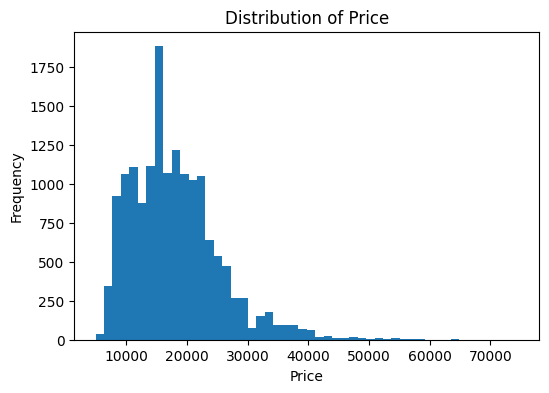

In [27]:
# Plot histograms for target feature
# Plot histograms for target feature
y=df["price"]
plt.figure(figsize=(6,4))
plt.hist(df['price'], bins=50)
plt.title("Distribution of Price")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()
#it is right skewed



**The target variable seems to be skewed. Perform suitable transformation on the target.**

In [28]:
df['price_log'] = np.log1p(df['price'])

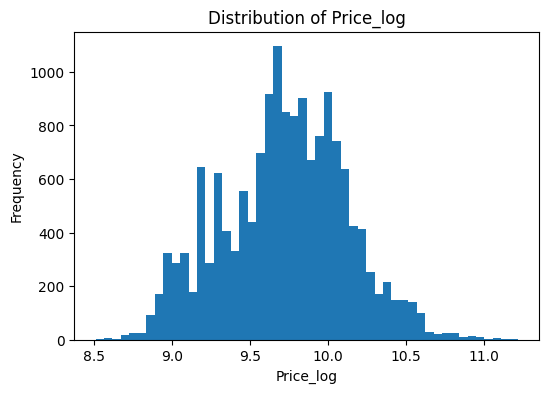

In [29]:
plt.figure(figsize=(6,4))
plt.hist(df['price_log'], bins=50)
plt.title("Distribution of Price_log")
plt.xlabel("Price_log")
plt.ylabel("Frequency")
plt.show()

In [30]:
# Transform the target feature

df["price_log"]

,price_log
0,9.665928
1,9.581973
2,9.591581
3,9.581973
4,9.728598
...,...
15910,10.595409
15911,10.593781
15912,10.593530
15913,10.589132


### **2.2 Correlation analysis** <font color = red> [6 marks] </font>

#### **2.2.1** <font color =red> [3 marks] </font>
Plot the correlation map between features and target variable.

In [31]:
# Visualise correlation

num_df = df.select_dtypes(include=['int64', 'float64'])

corr_matrix = num_df.corr()

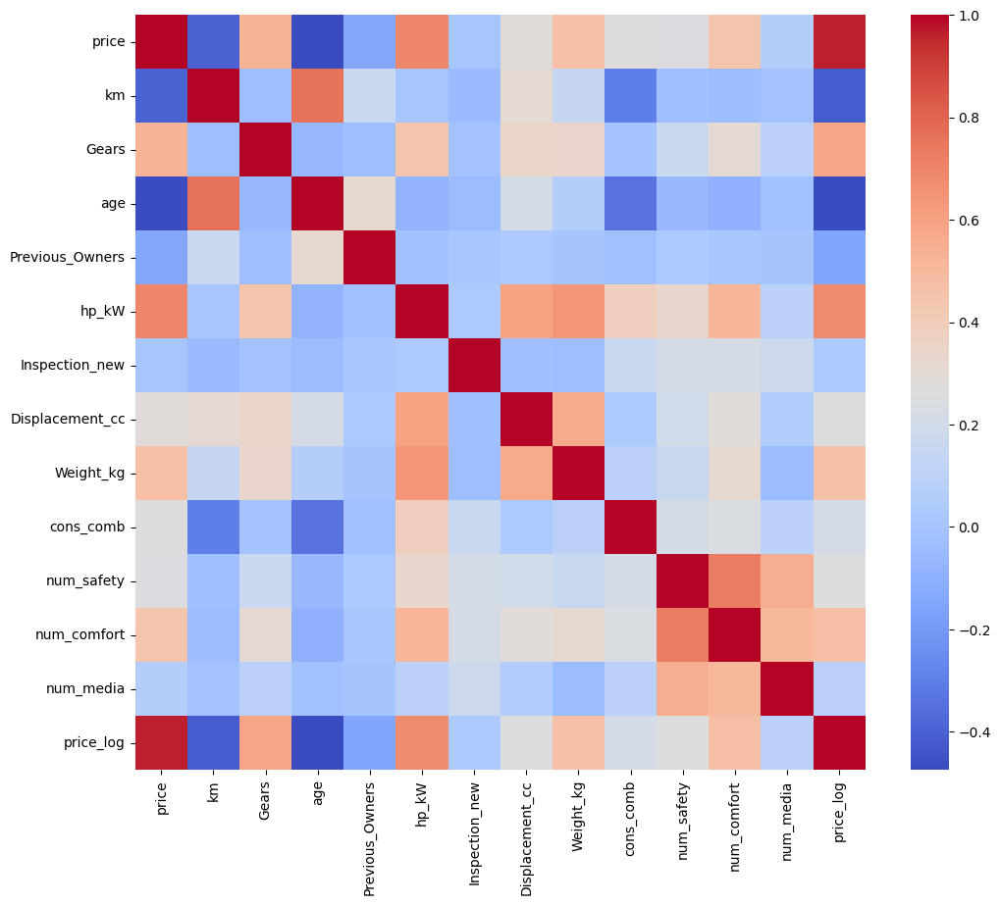

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,10))
sns.heatmap(corr_matrix, cmap='coolwarm')
plt.show()

#### **2.2.2** <font color =red> [3 marks] </font>
Analyse correlation between categorical features and target variable.

In [33]:
# Comparing average values of target for different categories

# Loop through all categorical columns and print their average target values
for col in df.select_dtypes(include=['object', 'category']).columns:
    print(f"\n--- Average price_log by {col} ---")
    print(df.groupby(col)['price_log'].mean().sort_values(ascending=False))


--- Average price_log by body_type ---
body_type
Van              10.294540
Station wagon     9.753456
Sedans            9.716144
Other             9.622932
Compact           9.555735
Name: price_log, dtype: float64

--- Average price_log by vat ---
vat
VAT deductible      9.730286
Price negotiable    9.556299
Name: price_log, dtype: float64

--- Average price_log by Type ---
Type
Almost New    9.928387
Used          9.630566
Name: price_log, dtype: float64

--- Average price_log by Fuel ---
Fuel
Diesel     9.734926
Benzine    9.709328
Other      9.639463
Name: price_log, dtype: float64

--- Average price_log by Paint_Type ---
Paint_Type
Metallic     9.725404
Uni/basic    9.638642
Other        9.144565
Name: price_log, dtype: float64

--- Average price_log by Upholstery_type ---
Upholstery_type
Part/Full Leather    9.981383
Cloth                9.642348
Name: price_log, dtype: float64

--- Average price_log by Gearing_Type ---
Gearing_Type
Semi-automatic    9.972004
Automatic         

### **2.3 Outlier analysis** <font color = red> [5 marks] </font>

#### **2.3.1** <font color =red> [2 marks] </font>
Identify potential outliers in the data.

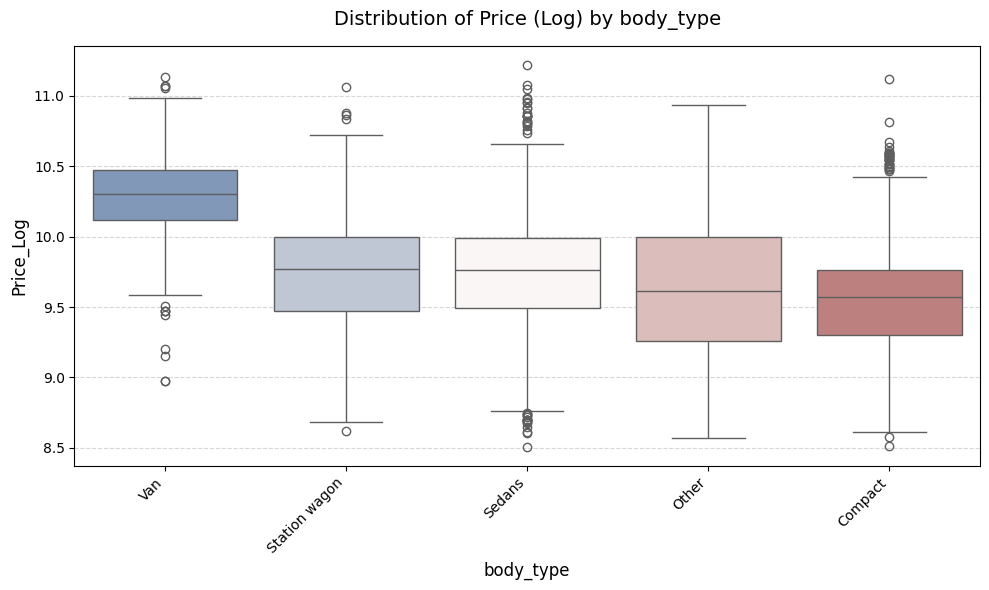

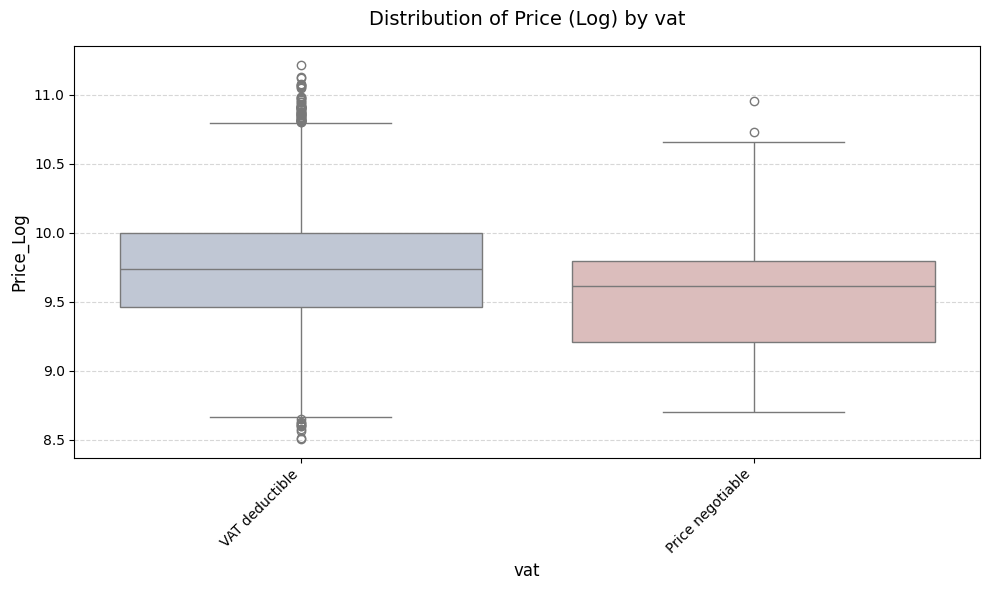

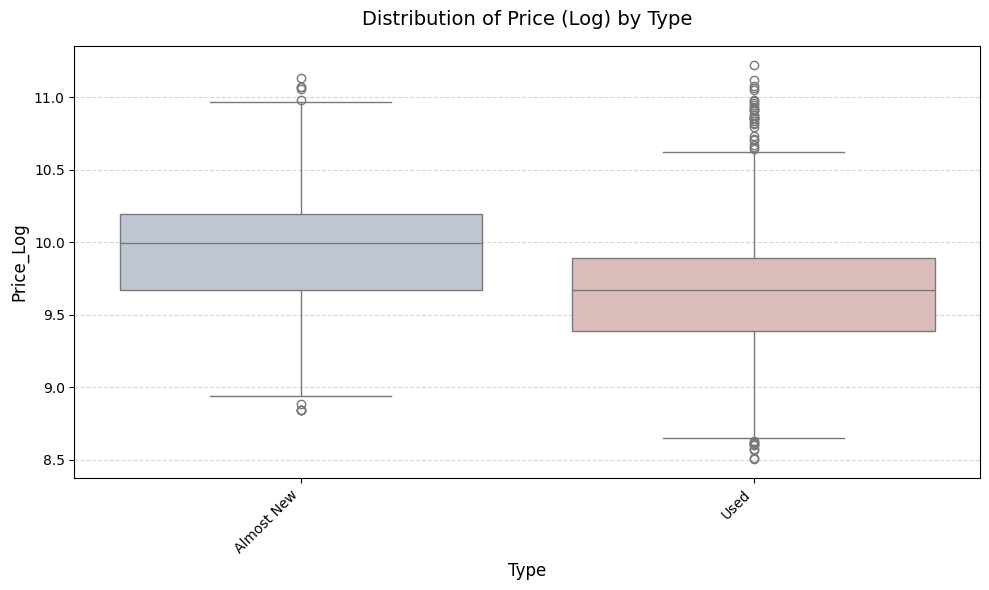

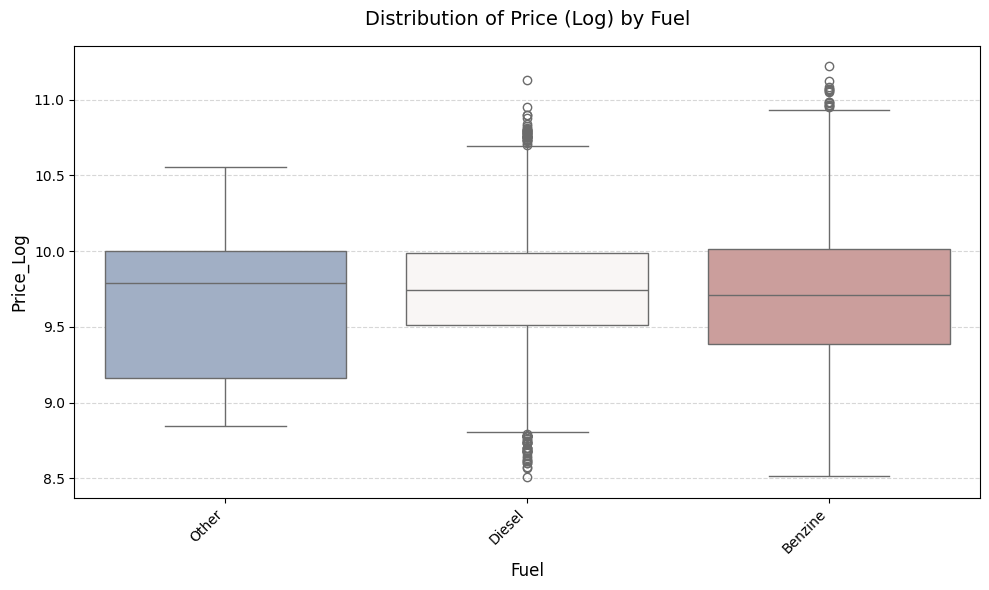

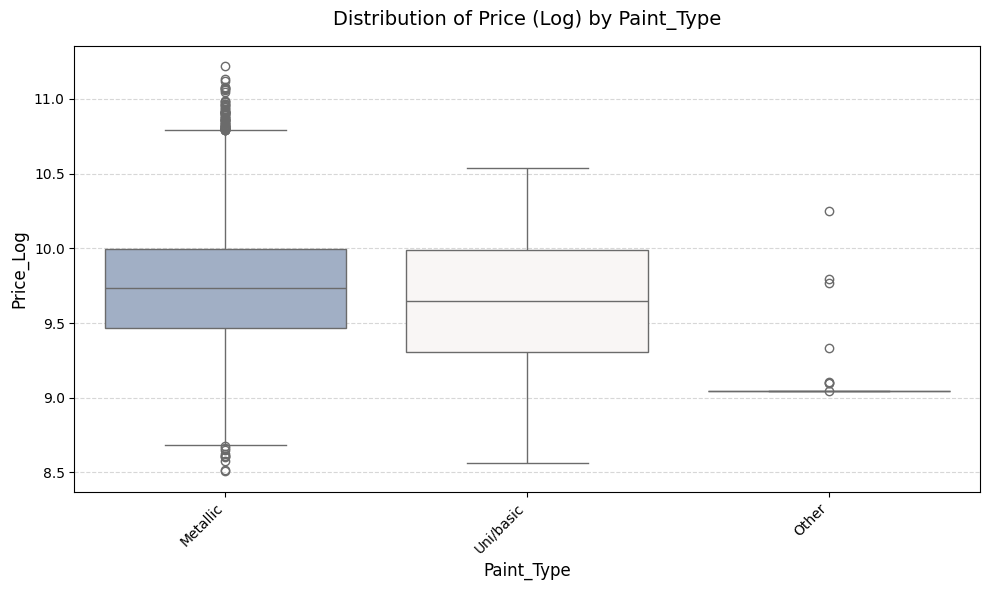

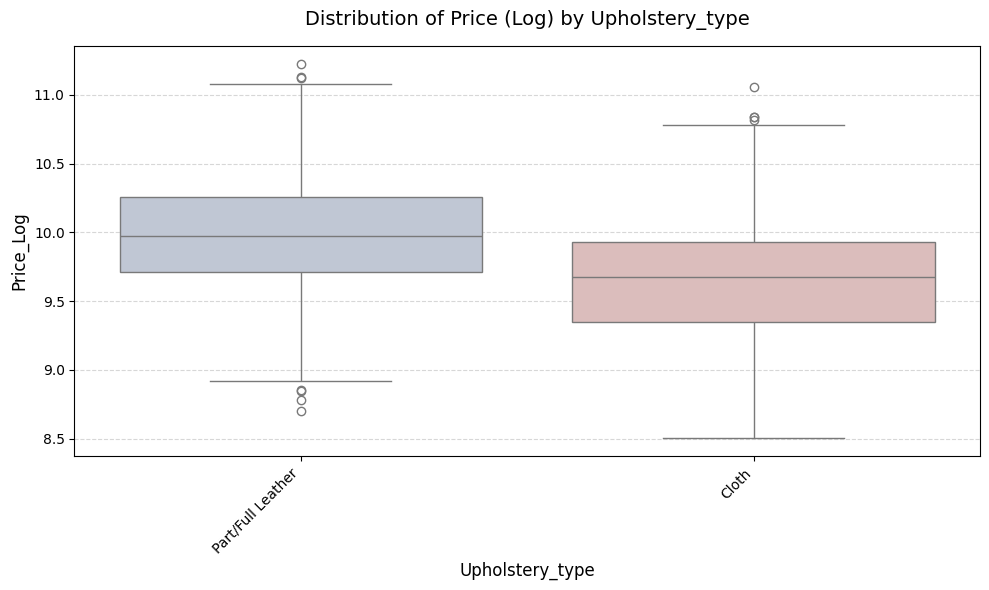

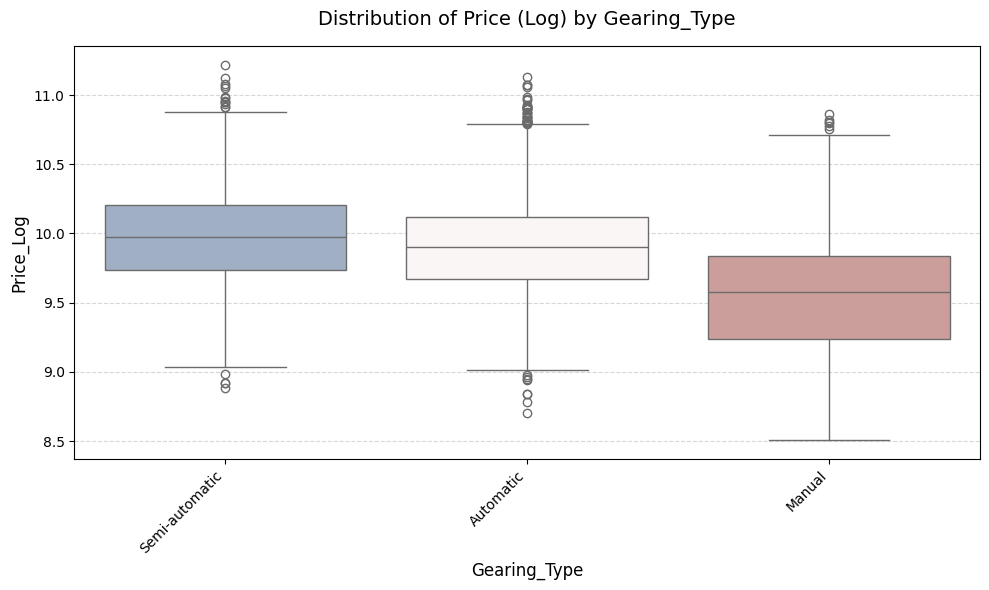

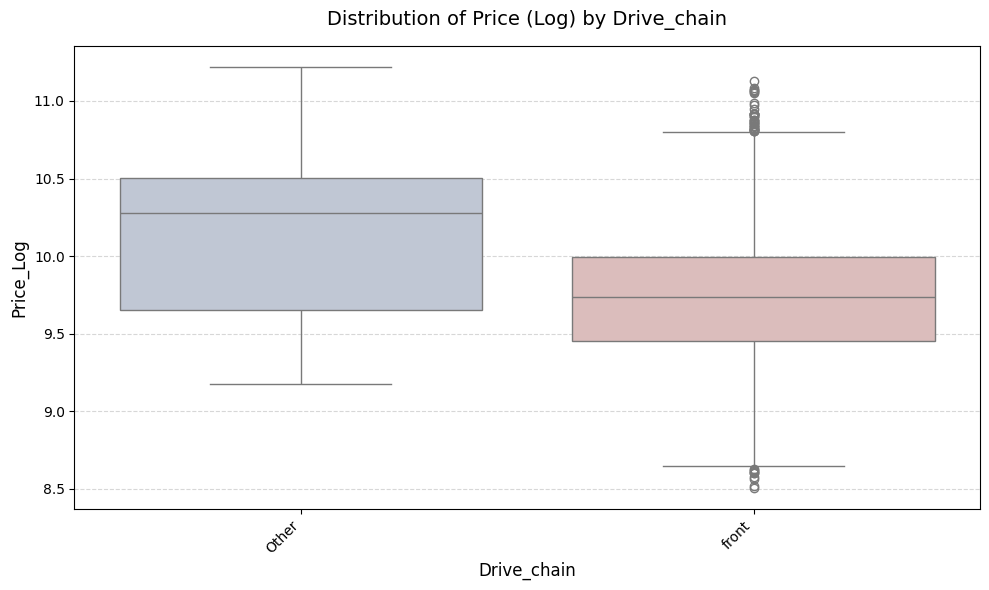

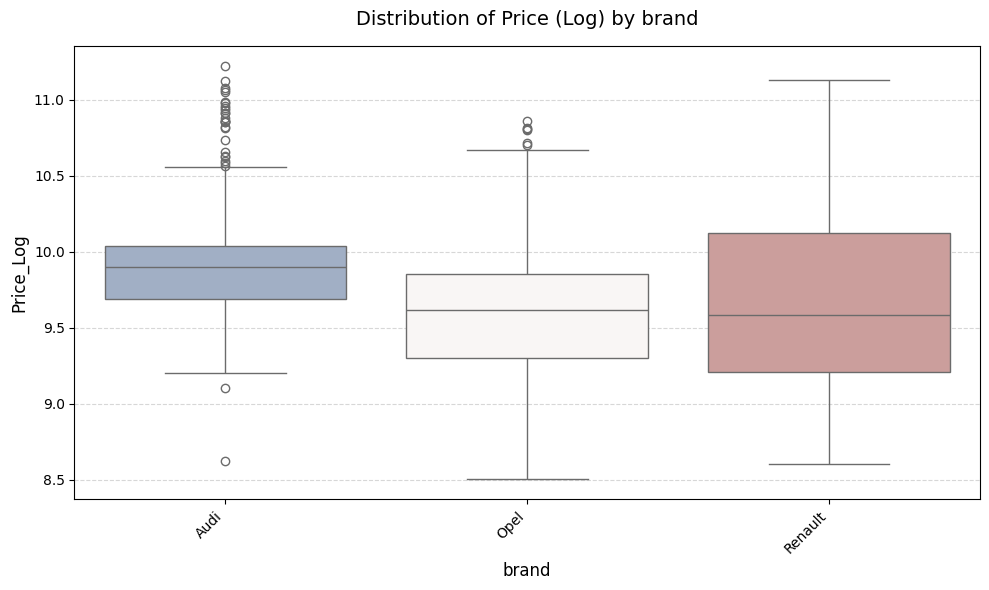

In [34]:
# 1. Dynamically get all categorical columns if you haven't defined 'cat_cols' yet
cat_cols = df.select_dtypes(include=['object', 'category']).columns

for col in cat_cols:
    # 2. Skip columns with too many unique categories (keeps plots readable)
    if df[col].nunique() > 12:
        print(f"Skipping '{col}' - too many unique categories ({df[col].nunique()}) to display cleanly.")
        continue

    plt.figure(figsize=(10, 6)) # Slightly wider to prevent label clipping

    # 3. Calculate the median for each group to sort the boxes cleanly
    group_order = df.groupby(col)['price_log'].median().sort_values(ascending=False).index

    # 4. Draw the sorted boxplot
    sns.boxplot(
        x=col,
        y='price_log',
        data=df,
        order=group_order,
        palette="vlag" # A nice balanced color palette for distributions
    )

    # 5. Clean up the formatting
    plt.xticks(rotation=45, ha='right') # 'ha=right' aligns text perfectly to the ticks
    plt.title(f"Distribution of Price (Log) by {col}", fontsize=14, pad=15)
    plt.xlabel(col, fontsize=12)
    plt.ylabel("Price_Log", fontsize=12)
    plt.grid(axis='y', linestyle='--', alpha=0.5) # Adds a soft grid for easier reading

    plt.tight_layout()
    plt.show()

#### **2.3.2** <font color =red> [3 marks] </font>
Handle the outliers suitably.

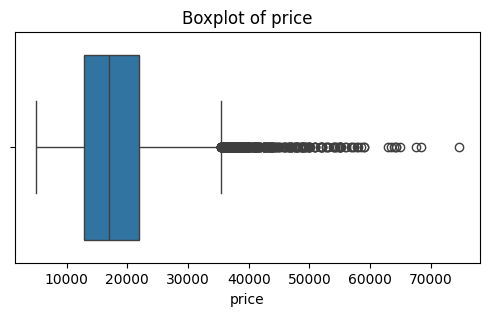

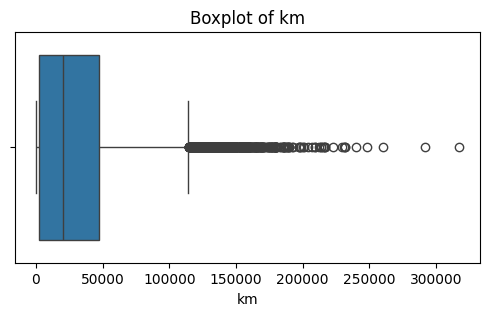

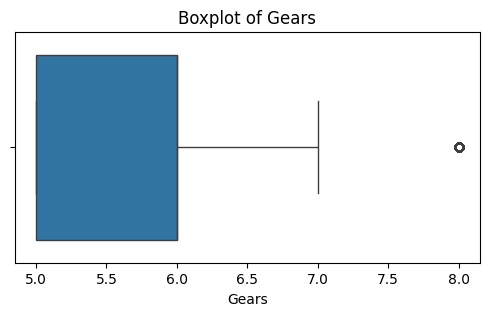

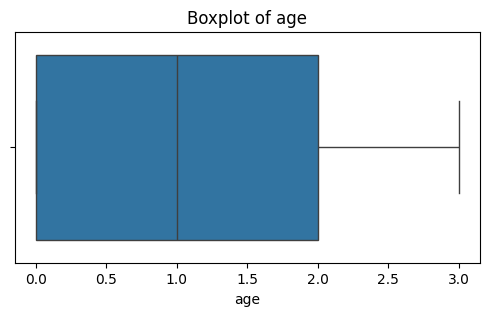

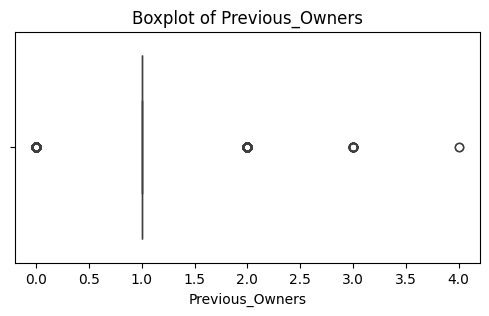

...

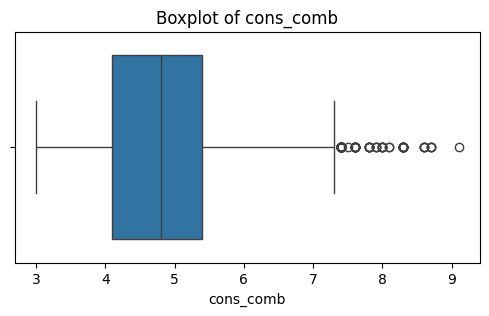

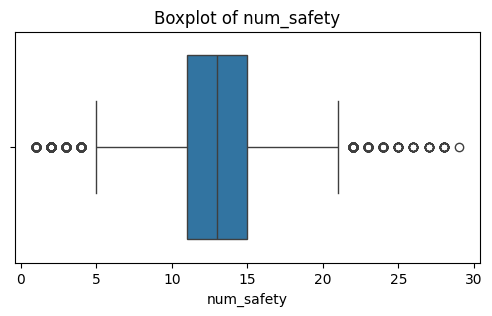

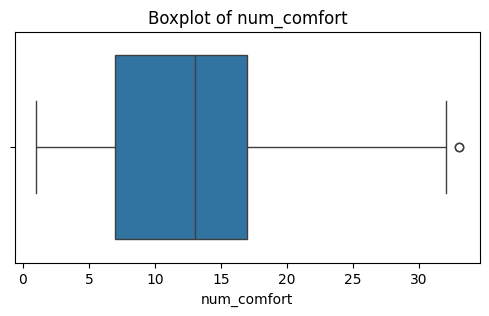

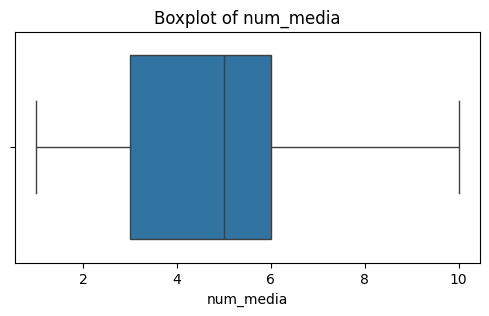

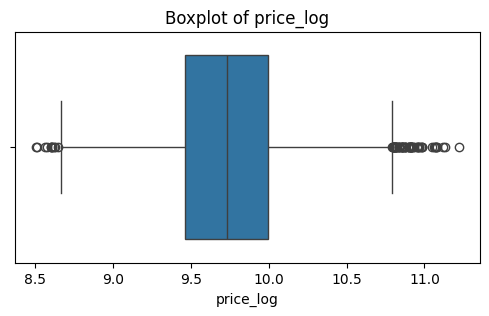

In [35]:
# Handle outliers

num_cols = df.select_dtypes(include=['int64', 'float64']).columns

for col in num_cols:
    plt.figure(figsize=(6,3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [36]:
def count_outliers(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    return len(outliers)

num_cols = df.select_dtypes(include=['int64', 'float64']).columns

outlier_counts = {}

for col in num_cols:
    outlier_counts[col] = count_outliers(df, col)



outlier_df = pd.DataFrame({
    'Column': outlier_counts.keys(),
    'Outlier_Count': outlier_counts.values()
})

outlier_df = outlier_df.sort_values(by='Outlier_Count', ascending=False)

print(outlier_df)

             Column  Outlier_Count
6    Inspection_new           3932
4   Previous_Owners           1757
10       num_safety            709
1                km            689
0             price            479
5             hp_kW            361
2             Gears            225
9         cons_comb            125
8         Weight_kg             87
13        price_log             71
7   Displacement_cc             21
11      num_comfort              2
3               age              0
12        num_media              0


In [37]:
df.columns

Index(['body_type', 'price', 'vat', 'km', 'Type', 'Fuel', 'Gears', 'age',
       'Previous_Owners', 'hp_kW', 'Inspection_new', 'Paint_Type',
       'Upholstery_type', 'Gearing_Type', 'Displacement_cc', 'Weight_kg',
       'Drive_chain', 'cons_comb', 'num_safety', 'num_comfort', 'num_media',
       'brand', 'price_log'],
      dtype='object')

In [38]:
cols_to_cap = ['km', 'hp_kW', 'num_safety']

for col in cols_to_cap:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower, upper)

### **2.4 Feature Engineering** <font color = red> [11 marks] </font>

#### **2.4.1**
Fix any redundant columns and create new ones if needed.

In [39]:
# Fix/create columns as needed


df = df.drop('price', axis=1)

In [40]:
df['power_per_cc'] = df['hp_kW'] / (df['Displacement_cc'] + 1)
df['km_per_year'] = df['km'] / (df['age'] + 1)
df['tfotal_features'] = (
    df['num_comfort'] +
    df['num_media'] +
    df['num_safety']
)

#### **2.4.2** <font color =red> [4 marks] </font>
Analysis and feature engineering on `['Comfort_Convenience', 'Entertainment_Media', 'Extras', 'Safety_Security']`.

These columns contains lists of features present. Decide on how to include these features in the predictors.

In [41]:
# Check unique values in each feature spec column
# 1. Select the columns you want to inspect (e.g., all categorical/object columns)
# If you want to check ALL columns instead, just use: spec_cols = data.columns
spec_cols = df.select_dtypes(include=['object', 'category']).columns

print("--- Unique Value Analysis ---")
for col in spec_cols:
    num_unique = df[col].nunique()
    print(f"\nColumn: '{col}' | Total Unique Values: {num_unique}")

    if num_unique <= 10:
        # Show the actual values if the list is short
        print(f"Values: {df[col].unique().tolist()}")
    else:
        # Show just a small sample if the list is long
        sample_vals = df[col].dropna().unique()[:5]
        print(f"Values (Sample of first 5): {list(sample_vals)}... [Truncated]")
print("\n" + "-"*30)


--- Unique Value Analysis ---

Column: 'body_type' | Total Unique Values: 5
Values: ['Sedans', 'Station wagon', 'Compact', 'Other', 'Van']

Column: 'vat' | Total Unique Values: 2
Values: ['VAT deductible', 'Price negotiable']

Column: 'Type' | Total Unique Values: 2
Values: ['Used', 'Almost New']

Column: 'Fuel' | Total Unique Values: 3
Values: ['Diesel', 'Benzine', 'Other']

Column: 'Paint_Type' | Total Unique Values: 3
Values: ['Metallic', 'Uni/basic', 'Other']

Column: 'Upholstery_type' | Total Unique Values: 2
Values: ['Cloth', 'Part/Full Leather']

Column: 'Gearing_Type' | Total Unique Values: 3
Values: ['Automatic', 'Manual', 'Semi-automatic']

Column: 'Drive_chain' | Total Unique Values: 2
Values: ['front', 'Other']

Column: 'brand' | Total Unique Values: 3
Values: ['Audi', 'Opel', 'Renault']

------------------------------


Out of these features, we will check the ones which are present in most of the cars or are absent from most of the cars. These kinds of features can be removed as they just increase the dimensionality without explaining the variance.

In [42]:
# Drop features from df

#original columns were dropped

#### **2.4.3** <font color =red> [3 marks] </font>
Perform feature encoding.

In [43]:
# Encode features

# Encode features
cat_cols = [
    'body_type',
    'vat',
    'Type',
    'Fuel',
    'Paint_Type',
    'Upholstery_type',
    'Gearing_Type',
    'Drive_chain',
    'brand'
]
#using one hot encoding

df = pd.get_dummies(df, columns=cat_cols, drop_first=True)


#### **2.4.4** <font color =red> [2 marks] </font>
Split the data into training and testing sets.

In [44]:
# Split data
# Split data
from sklearn.model_selection import train_test_split

X = df.drop('price_log', axis=1)
y = df['price_log']
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)


#### **2.4.5** <font color =red> [2 marks] </font>
Scale the features.

In [45]:
# Scale features

#scaling
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns
binary_cols = [col for col in num_cols if X_train[col].nunique() == 2]
num_cols = num_cols.drop(binary_cols)
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])


In [46]:
print(X_train.head())
print(X_test.head())

             km     Gears      age  Previous_Owners     hp_kW  Inspection_new  \
14306 -0.741835 -1.333437 -1.24355        -0.127049 -1.278689               0   
2582  -0.916383 -1.333437 -1.24355        -0.127049 -0.134375               0   
6302   1.223555 -1.333437  1.43032        -0.127049 -0.568425               0   
9156   0.535184 -1.333437  0.53903        -0.127049 -1.475984               0   
15663 -0.928354  0.087140 -0.35226        -0.127049  2.765867               0   

       Displacement_cc  Weight_kg  cons_comb  num_safety  ...  Fuel_Diesel  \
14306        -1.926653  -1.104615   0.194489   -0.746608  ...        False   
2582         -1.560687  -1.019218  -0.035569    0.306260  ...        False   
6302         -0.114940   0.432521  -0.380657   -1.009825  ...        False   
9156         -0.727299  -0.883589   0.539576   -1.009825  ...        False   
15663         1.334430   1.984726   2.265012    0.832694  ...        False   

       Fuel_Other  Paint_Type_Other  Paint_T

## **3 Linear Regression Models** <font color =red> [35 marks] </font>


### **3.1 Baseline Linear Regression Model** <font color =red> [10 marks] </font>

#### **3.1.1** <font color =red> [5 marks] </font>
Build and fit a basic linear regression model. Perform evaluation using suitable metrics.

In [47]:
# Initialise and train model
# Initialise and train model
from sklearn.linear_model import LinearRegression

lr = LinearRegression()

lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

In [48]:
#mse,rmse,r2 score

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MSE: 0.01489694659105748
RMSE: 0.12205304826614319
R2 Score: 0.9068017982189461


#### **3.1.2** <font color =red> [5 marks] </font>
Analyse residuals and check other assumptions of linear regression.

Check for linearity by analysing residuals vs predicted values

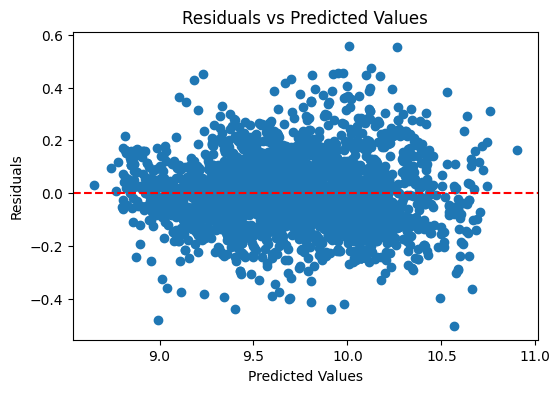

In [49]:
# Linearity check: Plot residuals vs fitted values

residuals = y_test - y_pred
plt.figure(figsize=(6,4))

plt.scatter(y_pred, residuals)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values")

plt.show()

Check normality in residual distribution

<Axes: xlabel='price_log', ylabel='Count'>

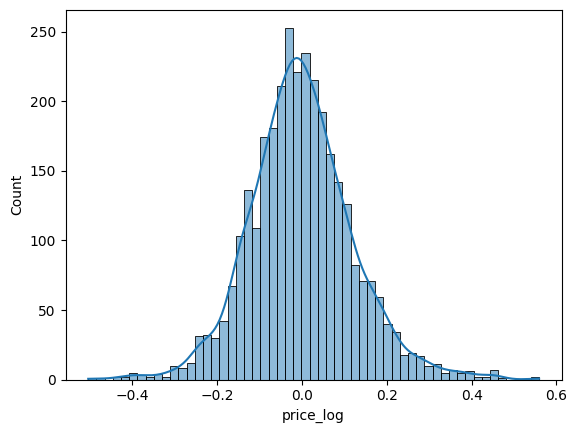

In [50]:
# Check the normality of residuals by plotting their distribution
sns.histplot(residuals, kde=True)


Check multicollinearity using Variance Inflation Factor (VIF) and handle features with high VIF.

In [51]:
import numpy as np
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1. Start fresh with a clean DataFrame copy
X_vif = pd.DataFrame(X_train, columns=X.columns).copy()

# 2. Force convert every column to numeric, turning text strings into NaN
X_vif = X_vif.apply(pd.to_numeric, errors='coerce')

# 3. Replace infinite values with NaN so we can deal with them uniformly
X_vif = X_vif.replace([np.inf, -np.inf], np.nan)

# 4. Fill missing values with the median for columns that are mostly numeric
X_vif = X_vif.fillna(X_vif.median())

# 5. CRITICAL FIX: Drop any columns that STILL contain a NaN
# (e.g., columns that were completely text or entirely empty)
X_vif = X_vif.dropna(axis=1, how='any')

# 6. Force the underlying array to a pure float64 datatype
X_vif = X_vif.astype(float)

print(f"Evaluating VIF on {X_vif.shape[1]} clean numeric columns...")

# 7. Run the VIF calculation loop safely
thresh = 5.0
dropped_features = []

while True:
    if X_vif.shape[1] == 0:
        print("No numeric features left to evaluate.")
        break

    # Calculate VIF
    vif_list = [
        variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])
    ]

    vif_data = pd.DataFrame({"Feature": X_vif.columns, "VIF": vif_list})
    vif_data = vif_data.sort_values(by="VIF", ascending=False)

    # Check the worst offender
    highest_vif = vif_data.iloc[0]["VIF"]
    highest_feature = vif_data.iloc[0]["Feature"]

    if highest_vif > thresh:
        print(f"Dropping '{highest_feature}' with high VIF of {highest_vif:.2f}")
        X_vif = X_vif.drop(columns=[highest_feature])
        dropped_features.append(highest_feature)
    else:
        break

print("\n--- Final Clean VIF Data ---")
print(vif_data.to_string(index=False))
print("-" * 35)
print(f"Total dropped columns due to multicollinearity: {dropped_features}")

Evaluating VIF on 31 clean numeric columns...
Dropping 'tfotal_features' with high VIF of inf
Dropping 'hp_kW' with high VIF of 123.01
Dropping 'Drive_chain_front' with high VIF of 28.36
Dropping 'km' with high VIF of 17.36
Dropping 'vat_VAT deductible' with high VIF of 10.64
Dropping 'Fuel_Diesel' with high VIF of 7.65

--- Final Clean VIF Data ---
                          Feature      VIF
                        Type_Used 4.522521
                       brand_Opel 3.626792
              Gearing_Type_Manual 3.437234
                      num_comfort 3.291550
                 body_type_Sedans 3.136879
          body_type_Station wagon 3.002326
                  Displacement_cc 2.648855
                              age 2.615920
                       num_safety 2.593079
                        Weight_kg 2.541352
                     power_per_cc 2.489763
                    brand_Renault 2.467393
                    body_type_Van 2.438696
                            Gears 2.247375
   

In [52]:
X_train = X_train.drop('tfotal_features', axis=1)
X_test = X_test.drop('tfotal_features', axis=1)

In [53]:
X_train = X_train.drop('km', axis=1)
X_test = X_test.drop('km', axis=1)

### **3.2 Ridge Regression Implementation** <font color =red> [10 marks] </font>

#### **3.2.1** <font color =red> [2 marks] </font>
Define a list of random alpha values

In [54]:
# List of alphas to tune for Ridge regularisation
from sklearn.linear_model import Ridge
alphas = [0.01, 0.1, 1, 10, 50, 100,150, 200]


#### **3.2.2** <font color =red> [4 marks] </font>
Apply Ridge Regularisation and find the best value of alpha from the list

In [55]:
# Applying Ridge regression
from sklearn.metrics import mean_squared_error, r2_score

ridge_results = {}

for alpha in alphas:
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train, y_train)

    y_pred_ridge = ridge.predict(X_test)
    y_train_pred = ridge.predict(X_train)

    mse = mean_squared_error(y_test, y_pred_ridge)
    r2 = r2_score(y_test, y_pred_ridge)
    r2_train=r2_score(y_train,y_train_pred)

    ridge_results[alpha] = {'MSE': mse, 'R2': r2,}

for alpha, result in ridge_results.items():
    print(f"Alpha: {alpha} → MSE: {result['MSE']:.4f}, R2: {result['R2']:.4f}")


Alpha: 0.01 → MSE: 0.0152, R2: 0.9046
Alpha: 0.1 → MSE: 0.0152, R2: 0.9046
Alpha: 1 → MSE: 0.0152, R2: 0.9046
Alpha: 10 → MSE: 0.0152, R2: 0.9046
Alpha: 50 → MSE: 0.0153, R2: 0.9041
Alpha: 100 → MSE: 0.0155, R2: 0.9029
Alpha: 150 → MSE: 0.0157, R2: 0.9015
Alpha: 200 → MSE: 0.0160, R2: 0.8999


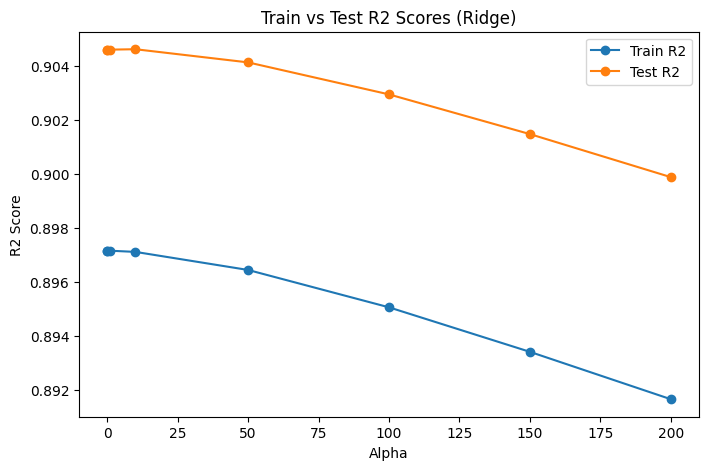

In [56]:
# Plot train and test scores against alpha

from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score

alphas = [0.01, 0.1, 1, 10, 50, 100, 150, 200]

train_scores = []
test_scores = []

for alpha in alphas:
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train, y_train)

    # Predictions
    y_train_pred = ridge.predict(X_train)
    y_test_pred = ridge.predict(X_test)

    # R2 scores
    train_scores.append(r2_score(y_train, y_train_pred))
    test_scores.append(r2_score(y_test, y_test_pred))




plt.figure(figsize=(8,5))

plt.plot(alphas, train_scores, marker='o', label='Train R2')
plt.plot(alphas, test_scores, marker='o', label='Test R2')

plt.xlabel("Alpha")
plt.ylabel("R2 Score")
plt.title("Train vs Test R2 Scores (Ridge)")
plt.legend()

plt.show()

Find the best alpha value.

In [57]:
# Best alpha value

from sklearn.model_selection import GridSearchCV

# Best score (negative MAE)
alphas = [0.01, 0.1, 1, 10, 50, 100]

ridge = Ridge()

grid = GridSearchCV(
    ridge,
    param_grid={'alpha': alphas},
    scoring='neg_mean_absolute_error',
    cv=5
)

grid.fit(X_train, y_train)



GridSearchCV(cv=5, estimator=Ridge(),
             param_grid={'alpha': [0.01, 0.1, 1, 10, 50, 100]},
             scoring='neg_mean_absolute_error')

In [58]:
print("Best Alpha:", grid.best_params_['alpha'])
print("Best Score (neg MAE):", grid.best_score_)

Best Alpha: 0.01
Best Score (neg MAE): -0.0954106465999191


We will get some best value of alpha above. This however is not the most accurate value but the best value from the given list. Now we have a rough estimate of the range that best alpha falls in. Let us do another iteration over the values in a smaller range.

#### **3.2.3** <font color =red> [4 marks] </font>
Fine tune by taking a closer range of alpha based on the previous result.

In [59]:
# Take a smaller range of alpha to test

alphas_fine = [0.5, 0.7, 0.9, 1, 1.1, 1.3, 1.5, 2]

In [60]:
# Applying Ridge regression
ridge = Ridge()

grid_fine = GridSearchCV(
    ridge,
    param_grid={'alpha': alphas_fine},
    scoring='neg_mean_absolute_error',
    cv=5
)

grid_fine.fit(X_train, y_train)


GridSearchCV(cv=5, estimator=Ridge(),
             param_grid={'alpha': [0.5, 0.7, 0.9, 1, 1.1, 1.3, 1.5, 2]},
             scoring='neg_mean_absolute_error')

In [61]:
print("Fine-tuned Alpha:", grid_fine.best_params_['alpha'])
print("Best Score (neg MAE):", grid_fine.best_score_)

# Convert to MAE
print("Best MAE:", -grid_fine.best_score_)

Fine-tuned Alpha: 0.5
Best Score (neg MAE): -0.09541781387533355
Best MAE: 0.09541781387533355


Plot the error-alpha graph again and find the actual optimal value for alpha.

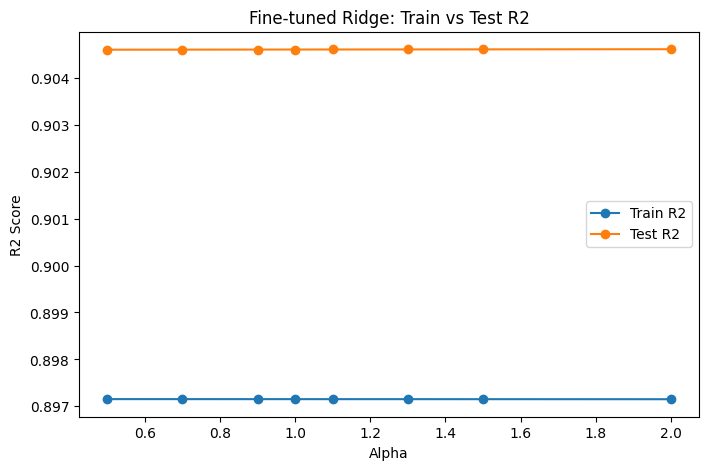

In [62]:
# Plot train and test scores against alpha,Best alpha value,Best score (negative MAE)
alphas_fine = [0.5, 0.7, 0.9, 1, 1.1, 1.3, 1.5, 2]

train_scores = []
test_scores = []

for alpha in alphas_fine:
    model = Ridge(alpha=alpha)
    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    train_scores.append(r2_score(y_train, y_train_pred))
    test_scores.append(r2_score(y_test, y_test_pred))

plt.figure(figsize=(8,5))
plt.plot(alphas_fine, train_scores, marker='o', label='Train R2')
plt.plot(alphas_fine, test_scores, marker='o', label='Test R2')

plt.xlabel("Alpha")
plt.ylabel("R2 Score")
plt.title("Fine-tuned Ridge: Train vs Test R2")
plt.legend()
plt.show()




In [63]:
# Set best alpha for Ridge regression
# Fit the Ridge model to get the coefficients of the fitted model
best_alpha=2
ridge_final = Ridge(alpha=best_alpha)

ridge_final.fit(X_train, y_train)


Ridge(alpha=2)

In [64]:
# Show the coefficients for each feature

coefficients = ridge_final.coef_


import pandas as pd

coef_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': coefficients
})

coef_df = coef_df.sort_values(by='Coefficient', key=abs, ascending=False)

print(coef_df)

                              Feature  Coefficient
28                      brand_Renault    -0.323633
27                         brand_Opel    -0.292937
16                      body_type_Van     0.246273
25        Gearing_Type_Semi-automatic     0.125062
1                                 age    -0.123598
19                        Fuel_Diesel     0.104747
3                               hp_kW     0.087497
24                Gearing_Type_Manual    -0.080797
11                       power_per_cc     0.076694
12                        km_per_year    -0.074651
21                   Paint_Type_Other     0.073335
9                         num_comfort     0.065961
20                         Fuel_Other     0.046844
23  Upholstery_type_Part/Full Leather     0.045964
6                           Weight_kg     0.039923
5                     Displacement_cc     0.026663
0                               Gears     0.024963
13                    body_type_Other     0.020884
10                          num

In [65]:
# Evaluate the Ridge model on the test data

y_test_pred = ridge_final.predict(X_test)
mse = mean_squared_error(y_test, y_test_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_test_pred)

print("Test MSE:", mse)
print("Test RMSE:", rmse)
print("Test R2:", r2)

Test MSE: 0.015247431303122717
Test RMSE: 0.12348048956463817
Test R2: 0.9046090975392083


### **3.3 Lasso Regression Implementation** <font color =red> [10 marks] </font>

#### **3.3.1** <font color =red> [2 marks] </font>
Define a list of random alpha values

In [66]:
# List of alphas to tune for Lasso regularisation
from sklearn.linear_model import Lasso
alphas = [0.0001, 0.001, 0.01, 0.1, 1]


#### **3.3.2** <font color =red> [4 marks] </font>
Apply Ridge Regularisation and find the best value of alpha from the list

In [67]:
# Initialise Lasso regression model
lasso_results = {}

for alpha in alphas:
    lasso = Lasso(alpha=alpha, max_iter=10000)
    lasso.fit(X_train, y_train)

    y_pred_lasso = lasso.predict(X_test)

    mse = mean_squared_error(y_test, y_pred_lasso)
    r2 = r2_score(y_test, y_pred_lasso)

    lasso_results[alpha] = {'MSE': mse, 'R2': r2}

# Print results
for alpha, result in lasso_results.items():
    print(f"Alpha: {alpha} → MSE: {result['MSE']:.4f}, R2: {result['R2']:.4f}")



Alpha: 0.0001 → MSE: 0.0152, R2: 0.9046
Alpha: 0.001 → MSE: 0.0154, R2: 0.9036
Alpha: 0.01 → MSE: 0.0220, R2: 0.8622
Alpha: 0.1 → MSE: 0.0622, R2: 0.6111
Alpha: 1 → MSE: 0.1599, R2: -0.0006


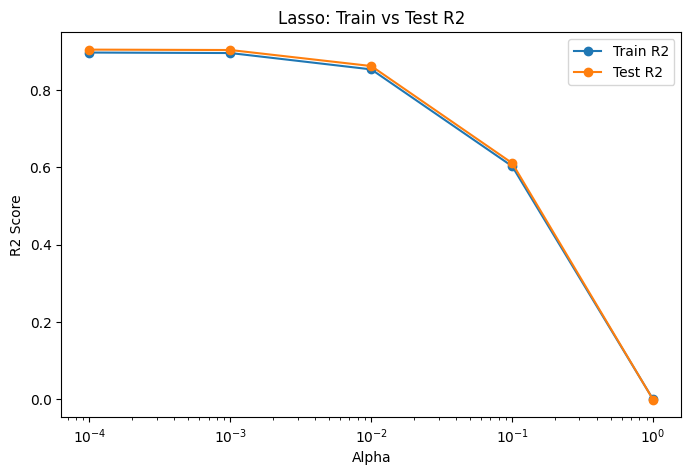

In [68]:
# Plot train and test scores against alpha
alphas = [0.0001, 0.001, 0.01, 0.1, 1]

train_scores = []
test_scores = []

for alpha in alphas:
    lasso = Lasso(alpha=alpha, max_iter=10000)
    lasso.fit(X_train, y_train)

    y_train_pred = lasso.predict(X_train)
    y_test_pred = lasso.predict(X_test)

    train_scores.append(r2_score(y_train, y_train_pred))
    test_scores.append(r2_score(y_test, y_test_pred))


plt.figure(figsize=(8,5))

plt.plot(alphas, train_scores, marker='o', label='Train R2')
plt.plot(alphas, test_scores, marker='o', label='Test R2')

plt.xlabel("Alpha")
plt.ylabel("R2 Score")
plt.title("Lasso: Train vs Test R2")
plt.legend()

plt.xscale('log')
plt.show()


In [69]:
# Best alpha value


# Best score (negative MAE)


alphas = [0.0001, 0.001, 0.01, 0.1, 1]

lasso = Lasso(max_iter=10000)

grid_lasso = GridSearchCV(
    lasso,
    param_grid={'alpha': alphas},
    scoring='neg_mean_absolute_error',
    cv=5
)

grid_lasso.fit(X_train, y_train)
print("Best Alpha:", grid_lasso.best_params_['alpha'])
print("Best Score (neg MAE):", grid_lasso.best_score_)

Best Alpha: 0.0001
Best Score (neg MAE): -0.09551471165735836


#### **3.3.3** <font color =red> [4 marks] </font>
Fine tune by taking a closer range of alpha based on the previous result.

In [70]:
# List of alphas to tune for Lasso regularization
alphas_fine = [0.00001, 0.00005, 0.0001, 0.0002, 0.0005,0.0006,0.0008]


In [71]:
# Tuning Lasso hyperparameters
lasso = Lasso(max_iter=10000)

grid_fine = GridSearchCV(
    lasso,
    param_grid={'alpha': alphas_fine},
    scoring='neg_mean_absolute_error',
    cv=5
)

grid_fine.fit(X_train, y_train)


GridSearchCV(cv=5, estimator=Lasso(max_iter=10000),
             param_grid={'alpha': [1e-05, 5e-05, 0.0001, 0.0002, 0.0005, 0.0006,
                                   0.0008]},
             scoring='neg_mean_absolute_error')

In [72]:
print("Fine-tuned Alpha:", grid_fine.best_params_['alpha'])
print("Best Score (neg MAE):", grid_fine.best_score_)
print("Best MAE:", -grid_fine.best_score_)

Fine-tuned Alpha: 1e-05
Best Score (neg MAE): -0.09541936806601031
Best MAE: 0.09541936806601031


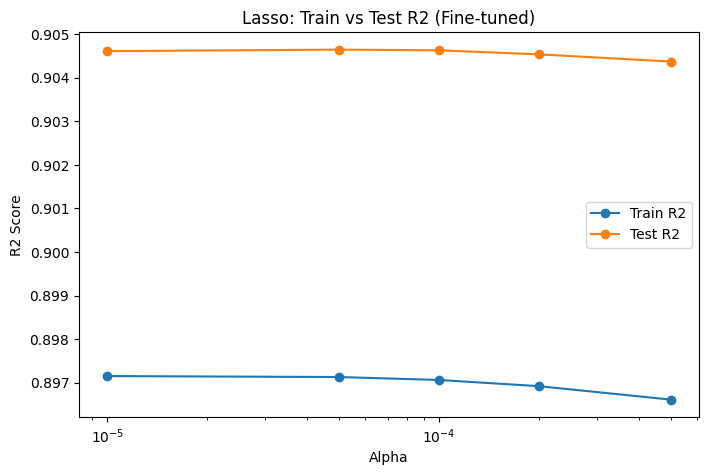

In [73]:
# Plot train and test scores against alpha

alphas_fine = [0.00001, 0.00005, 0.0001, 0.0002, 0.0005]

train_scores = []
test_scores = []

for alpha in alphas_fine:
    model = Lasso(alpha=alpha, max_iter=10000)
    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    train_scores.append(r2_score(y_train, y_train_pred))
    test_scores.append(r2_score(y_test, y_test_pred))

plt.figure(figsize=(8,5))

plt.plot(alphas_fine, train_scores, marker='o', label='Train R2')
plt.plot(alphas_fine, test_scores, marker='o', label='Test R2')

plt.xlabel("Alpha")
plt.ylabel("R2 Score")
plt.title("Lasso: Train vs Test R2 (Fine-tuned)")
plt.legend()

plt.xscale('log')  # very important for small alphas

plt.show()

In [74]:
# Set best alpha for Lasso regression


# Fit the Lasso model on scaled training data
# Get the coefficients of the fitted model
best_alpha_lasso=0.0002
lasso_final = Lasso(alpha=best_alpha_lasso, max_iter=10000)
lasso_final.fit(X_train, y_train)


Lasso(alpha=0.0002, max_iter=10000)

In [75]:
# Check the coefficients for each feature

coef_df_lasso = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': lasso_final.coef_
})


coef_df_lasso = coef_df_lasso.sort_values(by='Coefficient', key=abs, ascending=False)

print(coef_df_lasso)


                              Feature  Coefficient
28                      brand_Renault    -0.317559
27                         brand_Opel    -0.291231
16                      body_type_Van     0.229907
1                                 age    -0.123962
25        Gearing_Type_Semi-automatic     0.119722
3                               hp_kW     0.102299
19                        Fuel_Diesel     0.100358
24                Gearing_Type_Manual    -0.079722
12                        km_per_year    -0.074057
9                         num_comfort     0.065652
11                       power_per_cc     0.065061
23  Upholstery_type_Part/Full Leather     0.044831
6                           Weight_kg     0.042054
0                               Gears     0.026276
10                          num_media    -0.018787
5                     Displacement_cc     0.016757
7                           cons_comb     0.013915
8                          num_safety    -0.009999
14                   body_type_

In [76]:
# Evaluate the Lasso model on the test data
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

y_test_pred_lasso = lasso_final.predict(X_test)
mse = mean_squared_error(y_test, y_test_pred_lasso)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_test_pred_lasso)
r2 = r2_score(y_test, y_test_pred_lasso)

print("Lasso Test MSE:", mse)
print("Lasso Test RMSE:", rmse)
print("Lasso Test MAE:", mae)
print("Lasso Test R2:", r2)


Lasso Test MSE: 0.01525902882056517
Lasso Test RMSE: 0.123527441568929
Lasso Test MAE: 0.09341349572202712
Lasso Test R2: 0.9045365412093487


### **3.4 Regularisation Comparison & Analysis** <font color =red> [5 marks] </font>

#### **3.4.1** <font color =red> [2 marks] </font>
Compare the evaluation metrics for each model.

In [77]:
# Compare metrics for each model
# Import libraries


# Initialize models
lr = LinearRegression()
ridge = Ridge(alpha=2)
lasso = Lasso(alpha=0.0002, max_iter=10000)


lr.fit(X_train, y_train)
ridge.fit(X_train, y_train)
lasso.fit(X_train, y_train)


y_pred_lr = lr.predict(X_test)
y_pred_ridge = ridge.predict(X_test)
y_pred_lasso = lasso.predict(X_test)


def evaluate(y_true, y_pred):
    return [
        mean_squared_error(y_true, y_pred),
        np.sqrt(mean_squared_error(y_true, y_pred)),
        mean_absolute_error(y_true, y_pred),
        r2_score(y_true, y_pred)
    ]

# Create results DataFrame
results = pd.DataFrame(
    [
        evaluate(y_test, y_pred_lr),
        evaluate(y_test, y_pred_ridge),
        evaluate(y_test, y_pred_lasso)
    ],
    columns=["MSE", "RMSE", "MAE", "R2"],
    index=["Linear Regression", "Ridge Regression", "Lasso Regression"]
)


print(results)

print("\nBest Model (lowest MAE):", results["MAE"].idxmin())


                        MSE      RMSE       MAE        R2
Linear Regression  0.015250  0.123490  0.093411  0.904594
Ridge Regression   0.015247  0.123480  0.093415  0.904609
Lasso Regression   0.015259  0.123527  0.093413  0.904537

Best Model (lowest MAE): Linear Regression


#### **3.4.2** <font color =red> [3 marks] </font>
Compare the coefficients for the three models.

Also visualise a few of the largest coefficients and the coefficients of features dropped by Lasso.

In [78]:
# Compare highest coefficients and coefficients of eliminated features

coef_comparison = pd.DataFrame({
    "Feature": X_train.columns,
    "Linear": lr.coef_,
    "Ridge": ridge.coef_,
    "Lasso": lasso.coef_
})


coef_comparison = coef_comparison.sort_values(
    by="Linear", key=abs, ascending=False
)


print(coef_comparison)

                              Feature    Linear     Ridge     Lasso
28                      brand_Renault -0.325273 -0.323633 -0.317559
27                         brand_Opel -0.293593 -0.292937 -0.291231
16                      body_type_Van  0.248839  0.246273  0.229907
25        Gearing_Type_Semi-automatic  0.125722  0.125062  0.119722
1                                 age -0.123682 -0.123598 -0.123962
19                        Fuel_Diesel  0.105316  0.104747  0.100358
3                               hp_kW  0.088119  0.087497  0.102299
24                Gearing_Type_Manual -0.080955 -0.080797 -0.079722
21                   Paint_Type_Other  0.080524  0.073335  0.000000
11                       power_per_cc  0.076181  0.076694  0.065061
12                        km_per_year -0.074644 -0.074651 -0.074057
9                         num_comfort  0.065902  0.065961  0.065652
20                         Fuel_Other  0.048606  0.046844  0.001498
23  Upholstery_type_Part/Full Leather  0.045999 

In [79]:


#
coef_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Linear": lr.coef_,
    "Ridge": ridge.coef_,
    "Lasso": lasso.coef_
})


coef_df["Importance"] = coef_df["Linear"].abs()


coef_df = coef_df.sort_values(by="Importance", ascending=False)


top_features = coef_df.head(10)

print("Top Important Features:\n")
print(top_features[["Feature", "Linear", "Ridge", "Lasso"]])


eliminated_features = coef_df[coef_df["Lasso"] == 0]

print("\nFeatures Eliminated by Lasso:\n")
print(eliminated_features[["Feature", "Linear", "Ridge", "Lasso"]])

Top Important Features:

                        Feature    Linear     Ridge     Lasso
28                brand_Renault -0.325273 -0.323633 -0.317559
27                   brand_Opel -0.293593 -0.292937 -0.291231
16                body_type_Van  0.248839  0.246273  0.229907
25  Gearing_Type_Semi-automatic  0.125722  0.125062  0.119722
1                           age -0.123682 -0.123598 -0.123962
19                  Fuel_Diesel  0.105316  0.104747  0.100358
3                         hp_kW  0.088119  0.087497  0.102299
24          Gearing_Type_Manual -0.080955 -0.080797 -0.079722
21             Paint_Type_Other  0.080524  0.073335  0.000000
11                 power_per_cc  0.076181  0.076694  0.065061

Features Eliminated by Lasso:

                 Feature    Linear     Ridge  Lasso
21      Paint_Type_Other  0.080524  0.073335    0.0
13       body_type_Other  0.022514  0.020884    0.0
22  Paint_Type_Uni/basic -0.003542 -0.003452   -0.0
26     Drive_chain_front  0.000549  0.000432   -0.0


## **4 Conclusion & Key Takeaways**  <font color =red> [10 marks] </font>

What did you notice by performing regularisation? Did the model performance improve? If not, then why? Did you find overfitting or not? Was the data sufficent? Is a linear model sufficient?

#### **4.1 Conclude with outcomes and insights gained** <font color =red> [10 marks] </font>

Conclusion
-Regularisation (Ridge and Lasso) was applied to reduce overfitting and handle multicollinearity.

-It shrinks model coefficients and improves stability.

-Model performance didnt improve very much because No major overfitting was observed.

-Data was processed well and linear model achieved great performance with  low mse Train and test scores were very close.

-Residual plots showed no major issues.

-Yes, the dataset was sufficient: model had enough data to learn patterns.